In [1]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

Modules to reload:
all-except-skipped

Modules to skip:



In [2]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [3]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [86]:
diseases_id= load_sframe("Data/diseases_id.csv")
disease_names = SFrame.read_csv("Data/disease_names.csv")
gdb_diseases = SFrame.read_csv("Data/disease_gdb.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 100 lines in 0.034018 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,int]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 588 lines in 0.010047 secs.

...

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_gdb.csv

Parsing completed. Parsed 67 lines in 0.009877 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_gdb.csv

Parsing completed. Parsed 67 lines in 0.010107 secs.

In [87]:
def convert_to_barchart_format(sf,x, year_column="Year", count_column="count",  year_range=(1786,2019)):
    year_sf = SFrame()
    year_sf[year_column] = np.linspace(year_range[0],year_range[1],year_range[1]-year_range[0]+1).tolist()
    year_sf[year_column] = year_sf[year_column]
    sf[year_column] = sf[year_column].astype(float)
    res_sf = SFrame()
    for d in tqdm(sf[x].unique()):
        temp_sf = SFrame()
        temp_sf[x] = [d]*len(year_sf)
        temp_sf[year_column] = year_sf[year_column]
        res_sf = res_sf.append(temp_sf)
    sf = sf.join(res_sf,how="right").sort(year_column)
    sf = sf.fillna(count_column,0)
    df = sf.to_dataframe()
    df = df.sort_values([x,year_column])
    df['value'] = df.groupby([x])[count_column].cumsum()
    df["lastValue"] = df.groupby([x])["value"].shift(1)
    df = df.fillna(0)
    df["rank"] =df.groupby([year_column])["value"].rank(ascending=False)
    return df.rename(columns={x:"name", year_column: "year",count_column:"count"})[["year","name","value","lastValue","rank"]]

## Draw Graphs

In [8]:
import json
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import math
import glob
import ntpath
from tqdm import tqdm
from PIL import Image
from PIL import ImageFont
from PIL import ImageDraw

In [370]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr, diseases_id):
    for data in sf_corr.groupby("id"):
        if len(data[1]) >5:
            yield f"{data[0]}: {diseases_id[diseases_id['id']==data[0]][0]['Disease'].title()}", data[1].sort_values("year")

### To PDF

In [181]:
def create_pdf(temp_path,pdf_name):
    # imagelist is the list with all image filenames
    res = []
    image_list = glob.glob(os.path.join(temp_path, f"*.png"))
#     image_list.sort()
    for image_path in image_list:
        img = Image.open(image_path).convert("RGB")
        res.append(img)
        os.remove(image_path)

    res[0].save(f"{pdf_name}.pdf", "PDF", resolution=100.0, save_all=True, append_images=res[1:], quality=60, optimize=True)


def draw_probas_graph(graphs, output_name, output_folder, y_fields, time_field):
    rows = math.ceil(math.sqrt(len(graphs)))
    
    fig, axs = plt.subplots(rows, rows, figsize=(14, 14))
    matplotlib.rcParams.update({'font.size': 22})

    fig.subplots_adjust(left=0.08, right=0.98, wspace=0.3, hspace=0.3)
    titles = [t for t, _ in graphs]
    graphs = [g for _, g in graphs]
    try:
        axs = axs.flatten()
    except:
        axs = [axs]
    for title, data, ax in zip(titles, graphs, axs):

        x = data[time_field]
        for  l, y in y_fields.items():
            if not data[y].isnull().values.all():
                y = np.log(data[y])
                ax.plot(x, y ,linewidth=4  ,label=l)

        ax.xaxis.set_major_locator(plt.MaxNLocator(7, integer=True))
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        # plt.title(subreddit)
        # plt.ylabel('Average edge strength')
        # plt.xlabel('Graph number')
    plt.savefig(f'{output_folder}/{output_name}.png')
    plt.clf()

## Microsoft Academics

In [30]:
diseases_mag = load_sframe("Data/mag/diseases_mag.sframe")

In [ ]:
def join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","Paper publish year"], {"Number of papers": agg.COUNT()})
    diseases_pub_count_min_5 = diseases_mag[diseases_mag["Ref Number"] > 5].groupby(["disease","Paper publish year"], {"Number of papers (Ref >5)": agg.COUNT()})
    g = diseases_pub_count.join(diseases_pub_count_min_5)
    sf_corr = g.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","Paper publish year"], {"Number of papers":agg.SUM("Number of papers"), "Number of papers (Ref >5)":agg.SUM("Number of papers (Ref >5)")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","Paper publish year":"year"}).to_dataframe()

In [ ]:
sf_corr = join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences)

## Semantic Scholar

In [281]:
diseases_sm = load_sframe("Data/sm/diseases_sm.sframe")

### Citations to time

In [89]:
disease_citations = diseases_sm.stack("inCitations",new_column_name=["cite paper id", "cite year"], drop_na=True)

In [90]:
disease_citations = disease_citations.groupby(["disease","cite year"], {"Citations": agg.COUNT("cite paper id")})

In [91]:
disease_citations["cite year"] = disease_citations["cite year"].astype(int)

In [92]:
disease_citations = disease_citations.rename({"cite year": "year"})

In [93]:
disease_citations

year,disease,Citations
2007,Venezuelan equineencephalitis ...,131
2012,Parainfluenza virus,313
2018,Angiostrongyliasis,73
1995,Gastroenteritis,42
1998,Diphtheria,76
1949,Escherichia coli diarrhea,1
2013,Brazilian purpuric fever,1
1957,Diphtheria,1
2003,Fungal infection,84
1984,Malaria,37


In [94]:
citations_year = disease_citations.groupby(["year"], operations={"Total Citations": agg.SUM("Citations")})

In [95]:
citations_year["year"] = citations_year["year"].astype(int)

In [96]:
disease_citations

year,disease,Citations
2007,Venezuelan equineencephalitis ...,131
2012,Parainfluenza virus,313
2018,Angiostrongyliasis,73
1995,Gastroenteritis,42
1998,Diphtheria,76
1949,Escherichia coli diarrhea,1
2013,Brazilian purpuric fever,1
1957,Diphtheria,1
2003,Fungal infection,84
1984,Malaria,37


In [97]:
citations_year.sort("Total Citations",False)

year,Total Citations
2017,902792
2016,802772
2018,801145
2015,765356
2014,698638
2013,621743
2012,543889
2019,502158
2011,448514
2010,359791


In [98]:
import turicreate as tc
tc.visualization.scatter(citations_year["year"], citations_year["Total Citations"])

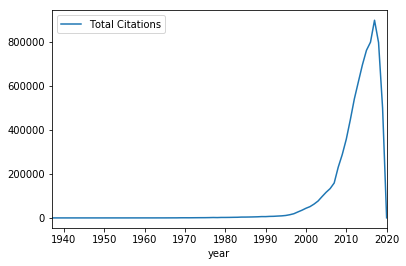

In [42]:
citations_year.to_dataframe().sort_values("year").plot(x="year", y="Total Citations")

In [99]:
disease_citations = disease_citations.join(citations_year)

In [100]:
disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]

In [102]:
disease_citations

year,disease,Citations,Total Citations,Citations Norm,id
2007,Venezuelan equineencephalitis ...,131,159660,0.0008204935487911813,18
2012,Parainfluenza virus,313,543889,0.0005754850714024368,80
2018,Angiostrongyliasis,73,801145,9.111958509383445e-05,270
1995,Gastroenteritis,42,11205,0.003748326639892905,119
1998,Diphtheria,76,27320,0.0027818448023426063,299
1949,Escherichia coli diarrhea,1,14,0.07142857142857142,17
2013,Brazilian purpuric fever,1,621743,1.6083815981844589e-06,211
1957,Diphtheria,1,79,0.012658227848101266,299
2003,Fungal infection,84,77162,0.001088618750161997,19
1984,Malaria,37,3775,0.00980132450331126,286


In [101]:
disease_citations = disease_citations.join(disease_names)

In [103]:
citations_race = convert_to_barchart_format(disease_citations,"disease",year_column="year",count_column="Citations" )

In [104]:
citations_race.to_csv("output/Papers/citations_race3.csv", index=False)

In [105]:
disease_citations.groupby(["disease"], {"Citations": agg.SUM("Citations")}).sort("Citations",False)

disease,Citations
HIV/AIDS,1590535
Escherichia coli diarrhea,663911
Tuberculosis,547434
Influenza,530946
Malaria,415225
Hepatitis C,408378
Hepatitis B,245097
Pneumonia,224350
Dengue,180955
Cytomegalovirus,133334


### Publications Corrolation GDB

In [172]:
gdb = SFrame.read_csv("Data/gdb/gdb.csv")
# gdb["cause"] = gdb["cause"].apply(lambda x: x.lower())

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 100 lines in 0.110602 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,str,str,str,str,str,int,float,float,float]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 22176 lines in 0.044177 secs.

In [173]:
gdb = gdb[(gdb["metric"]=="Rate")&(gdb["sex"]=="Both")]

In [174]:
gdb["cause"] = gdb["cause"].apply(lambda x: x.strip().lower())

In [175]:
gdb_diseases["GDB_lower"] = gdb_diseases["GDB"].apply(lambda x: x.lower())

In [166]:
# gbd = gdb.join(gdb_diseases, on={"cause":"GDB_lower"})

In [282]:
diseases_sm_gdb = diseases_sm.join(gdb_diseases, {"id":"id"})

In [179]:
def join_gdb(academic_sf, diseases_occurrences):
    diseases_pub_count = academic_sf.groupby(["GDB_lower","year"], {"Number of papers": agg.COUNT()})
#     sf_corr = diseases_pub_count.join(diseases_id)
#     sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return diseases_pub_count.join(diseases_occurrences, on={"GDB_lower":"cause","year":"year"}).to_dataframe()

In [197]:
sm_gdb = join_gdb(diseases_sm_gdb, gdb)

In [198]:
sm_gdb = sm_gdb.drop(columns=["sex","age","upper","lower","location","metric"])

In [199]:
sm_gdb = sm_gdb[sm_gdb["measure"]=="DALYs (Disability-Adjusted Life Years)"]

Normlize paper number:

In [201]:
diseases_sm

paper id,sources,title,venue,year
c491f893ebdd0b423e9a5f4689382f535670dfff ...,[Medline],Longitudinal genomicsurveillance of ...,Genome Biology,2017
0f1951b30eaf1bca60d50f0b44b291589c98ced5 ...,[],HIV/AIDS: The ZimbabweanSituation and Trends ...,,2013
0f1951b30eaf1bca60d50f0b44b291589c98ced5 ...,[],HIV/AIDS: The ZimbabweanSituation and Trends ...,,2013
3ce84555a29993bdd3d2cf84a8e67ebeeb835eae ...,[Medline],Cost-EffectivenessAnalysis of Prophylactic ...,PharmacoEconomics,2011
2f7b33f603e80fb82edd631338340dd14dadbab8 ...,[Medline],"Human papillomavirusprevalence, viral load ...",The Brazilian journal ofinfectious diseases : an ...,2002
bd592779a2227846ee3b81a0b846955b4d909498 ...,[Medline],Factors Associated withImmunological Discord ...,Japanese journal ofinfectious diseases ...,2015
00e1f9a87e4043c7ce6626155b572b68efebf5dd ...,[],Seroprevalence of HIV inANC clinic attendees and ...,,2017
b246cc0c3fe8fdff761383afcf8da052d5db88a9 ...,[Medline],The effects of earlysyphilis on CD4 counts ...,Sexually transmittedinfections ...,2005
b246cc0c3fe8fdff761383afcf8da052d5db88a9 ...,[Medline],The effects of earlysyphilis on CD4 counts ...,Sexually transmittedinfections ...,2005
8f16bd9459d054b372ee35c0b643e0c02f64224d ...,[],The effect of the votingfranchise on public ...,,2008


In [283]:
diseases_pub_count = diseases_sm.groupby(["disease","year"], {"Number of papers": agg.COUNT()})


In [284]:
papers_year = diseases_sm.groupby("year", {"Total Number of papers": agg.COUNT()})

In [285]:
diseases_pub_count = diseases_pub_count.join(papers_year,{"year":"year"})


In [286]:
diseases_pub_count["NPR"] = diseases_pub_count["Number of papers"] / diseases_pub_count["Total Number of papers"]

In [155]:
# pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

In [225]:
sm_gdb = sm_gdb.merge(papers_year.to_dataframe(),left_on="year", right_on="year")

In [226]:
sm_gdb["NPR"] = sm_gdb["Number of papers"] / sm_gdb["Total Number of papers"]

Join with Promed

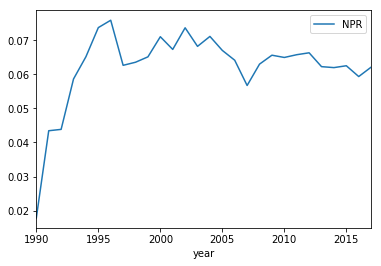

In [231]:
sm_gdb[sm_gdb["GDB_lower"]=="acute hepatitis c"].sort_values("year").plot(x="year", y="NPR")

### Publications - Citation

In [234]:
sm_gdb["val"] = sm_gdb["val"].fillna(0)

In [239]:
gdb_diseases

id,disease,GDB,GDB_lower
101,Ascariasis,Ascariasis,ascariasis
73,Bacillus cereus foodpoisoning ...,Diarrheal diseases,diarrheal diseases
12,Borna virus encephalitis,Encephalitis,encephalitis
23,Brainerd diarrhea,Diarrheal diseases,diarrheal diseases
244,California encephalitis,Encephalitis,encephalitis
42,Campylobacteriosis,Diarrheal diseases,diarrheal diseases
201,Chlamydia,Chlamydial infection,chlamydial infection
331,Cysticercosis,Cysticercosis,cysticercosis
79,Dengue,Dengue,dengue
299,Diphtheria,Diphtheria,diphtheria


In [244]:
disease_citations_gdb = disease_citations.join(gdb_diseases, {"id":"id"})

In [247]:
disease_citations_gdb = disease_citations_gdb.groupby(["GDB_lower", "year"],{"Citations":agg.SUM("Citations"),"Total Citations":agg.SELECT_ONE("Total Citations")})

In [248]:
disease_citations_gdb["NCR"] = disease_citations_gdb["Citations"] / disease_citations_gdb["Total Citations"]

In [251]:
disease_citations_gdb["year"] = disease_citations_gdb["year"].astype(int)

In [252]:
pubmed_gdb_citation = SFrame(sm_gdb).join(disease_citations_gdb, on={"GDB_lower":"GDB_lower", "year":"year"})

In [253]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"val":"DALY"})

#### NPR

In [254]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"year":"Year"})

In [255]:
diseases_pub_count

disease,year,Number of papers,Total Number of papers,Normalized Number ofpapers ...
Eastern equineencephalitis ...,2007,17,11508,0.0014772332290580465
Trachoma,2007,22,11508,0.0019117135905457074
Dengue,1956,1,65,0.015384615384615385
Bacillus cereus foodpoisoning ...,2007,51,11508,0.0044316996871741395
Trichuriasis,2004,1,8150,0.0001226993865030675
Dengue,2004,150,8150,0.018404907975460124
Ascariasis,1954,1,60,0.016666666666666666
Gonococcal,1984,46,826,0.05569007263922518
Diphtheria,2015,61,32056,0.0019029198901921638
Trichuriasis,2018,1,29405,3.4007821799013776e-05


In [291]:
diseases_pub_count = diseases_pub_count.rename({"year":"Year", "disease":"Disease"})

In [261]:
diseases_pub_count = diseases_pub_count.sort(["Disease","Year"])

In [263]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"GDB_lower":"Disease"})

In [265]:
pubmed_gdb_citation = pubmed_gdb_citation.sort(["Disease","Year"])

In [268]:
pubmed_gdb_citation_log = pubmed_gdb_citation.copy()

In [269]:
pubmed_gdb_citation_log["NPR"] = np.log(pubmed_gdb_citation3["NPR"] )
pubmed_gdb_citation_log["NCR"] = np.log(pubmed_gdb_citation3["NCR"] )

In [381]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [380]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")
def create_gird(df, col, hue,x,y, sharey=False):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette="tab20c",
                         col_wrap=5, height=4.5,sharey=sharey)

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

In [296]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(diseases_pub_count.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NPR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

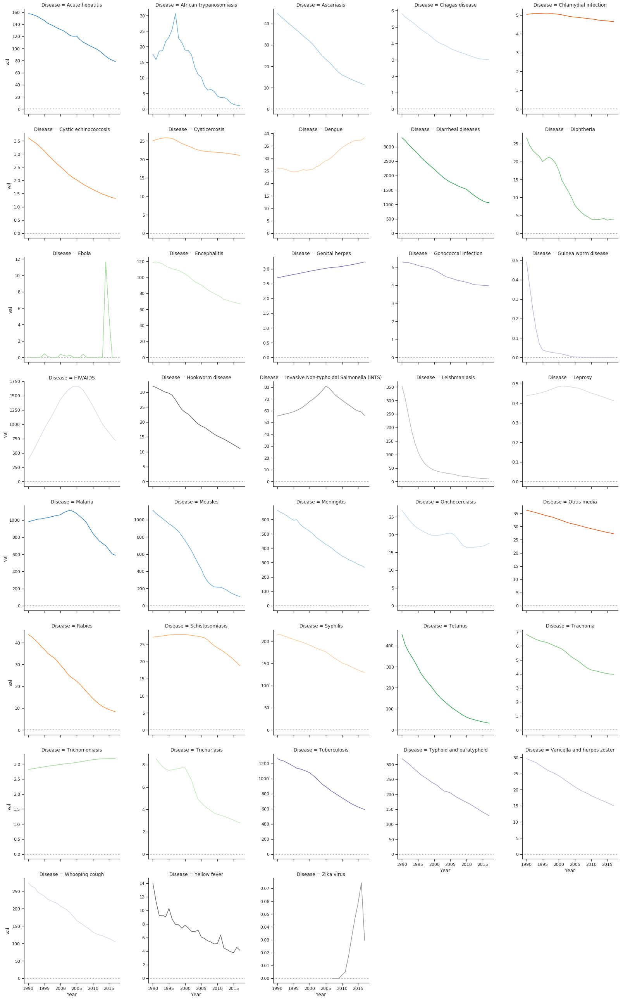

In [95]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")


# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(pubmed_gdb_citation[pubmed_gdb_citation["Year"]>=1900][["Year","Disease","val"]], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "val")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

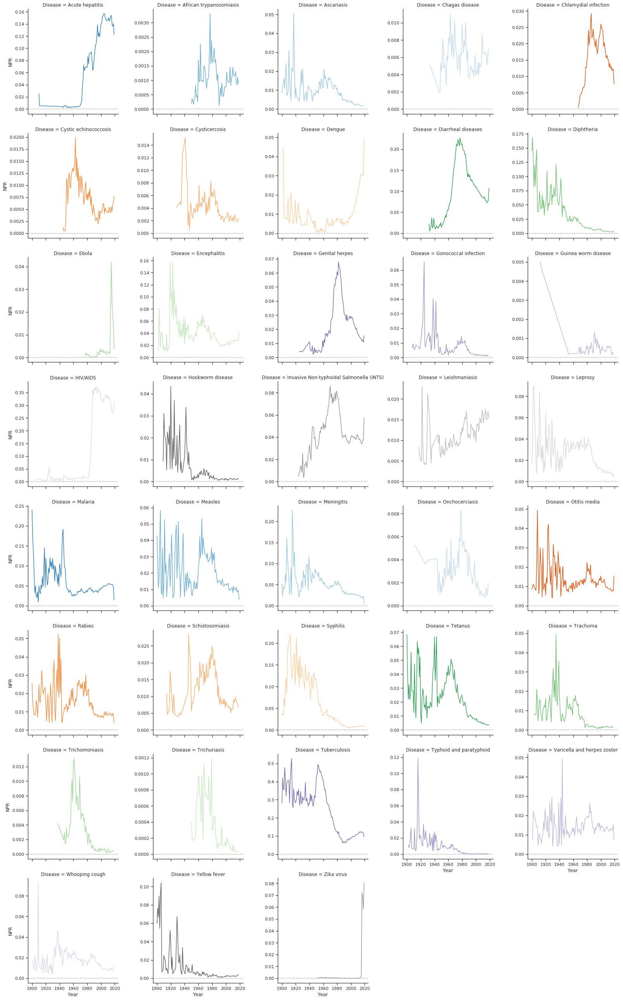

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count[diseases_pub_count["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [312]:
diseases_pub_count_df = diseases_pub_count.to_dataframe().sort_values(["Disease", "Year"])

In [321]:
diseases_pub_count_smooth= diseases_pub_count_df[["Disease","Number of papers","Total Number of papers"]].groupby("Disease").rolling(5).mean()

In [322]:
diseases_pub_count_smooth = diseases_pub_count_smooth.reset_index()

In [323]:
diseases_pub_count_smooth["Year"] = diseases_pub_count_df["Year"].values

In [325]:
diseases_pub_count_smooth["NPR"] = diseases_pub_count_smooth["Number of papers"]/diseases_pub_count_smooth["Total Number of papers"]

In [326]:
diseases_pub_count_smooth = diseases_pub_count_smooth.sort_values(["Disease", "Year"])

In [328]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NPR_smooth.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(diseases_pub_count_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NPR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

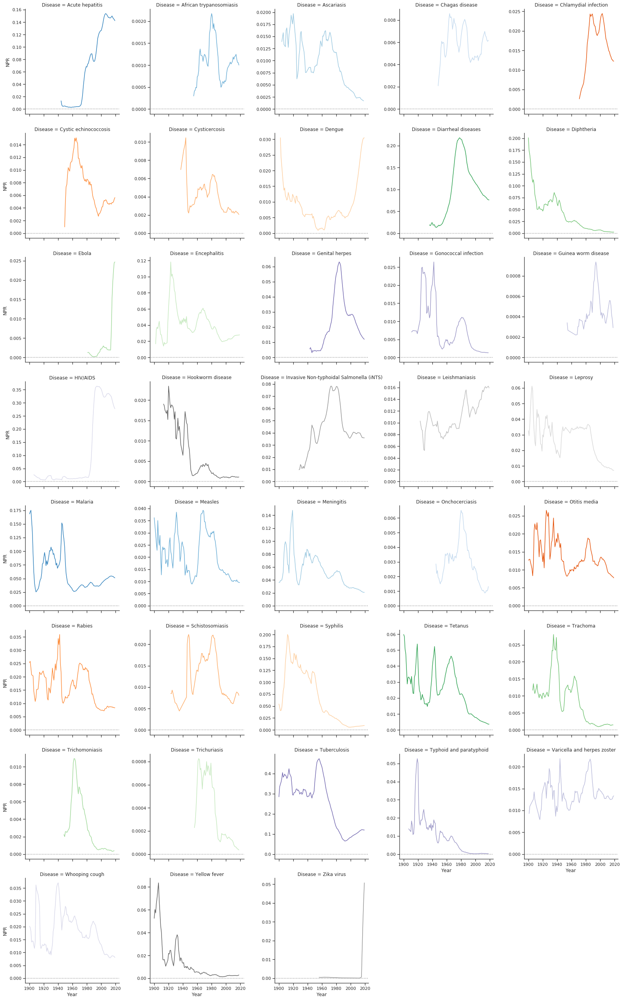

In [392]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count_smooth[diseases_pub_count_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots


#### NCR

In [329]:
disease_citations

year,disease,Citations,Total Citations,Citations Norm,id
2007.0,Venezuelan equineencephalitis ...,131,159660,0.0008204935487911813,18
2012.0,Parainfluenza virus,313,543889,0.0005754850714024368,80
2018.0,Angiostrongyliasis,73,801145,9.111958509383445e-05,270
1995.0,Gastroenteritis,42,11205,0.003748326639892905,119
1998.0,Diphtheria,76,27320,0.0027818448023426063,299
1949.0,Escherichia coli diarrhea,1,14,0.07142857142857142,17
2013.0,Brazilian purpuric fever,1,621743,1.6083815981844589e-06,211
1957.0,Diphtheria,1,79,0.012658227848101266,299
2003.0,Fungal infection,84,77162,0.001088618750161997,19
1984.0,Malaria,37,3775,0.00980132450331126,286


In [331]:
disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR", "disease": "Disease"})
disease_citations = disease_citations.join(disease_names, {"id":"id"})
disease_citations = disease_citations.sort(["Disease", "Year"])

In [332]:
disease_citations = disease_citations.to_dataframe()

In [333]:
disease_citations = disease_citations[disease_citations["Year"].notna()]

In [336]:
disease_citations = disease_citations[disease_citations["Year"]<2019]

In [337]:
disease_citations = disease_citations.reset_index()

In [339]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NCR.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(disease_citations))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NCR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

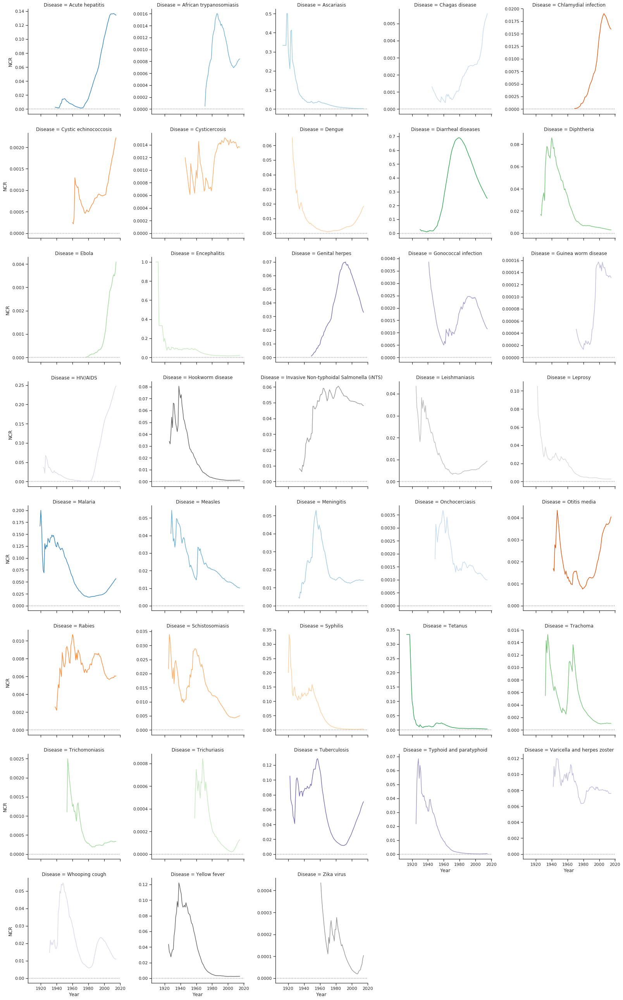

In [343]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations[disease_citations["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [340]:
disease_citations_smooth= disease_citations[["Disease","Citations","Total Citations"]].groupby("Disease").rolling(5).mean()

In [341]:
disease_citations_smooth = disease_citations_smooth.reset_index()

In [342]:
disease_citations_smooth["Year"] = disease_citations["Year"]

In [343]:
disease_citations_smooth["NCR"] = disease_citations_smooth["Citations"]/disease_citations_smooth["Total Citations"]

In [344]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/NCR_smooth.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(disease_citations_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "NCR")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

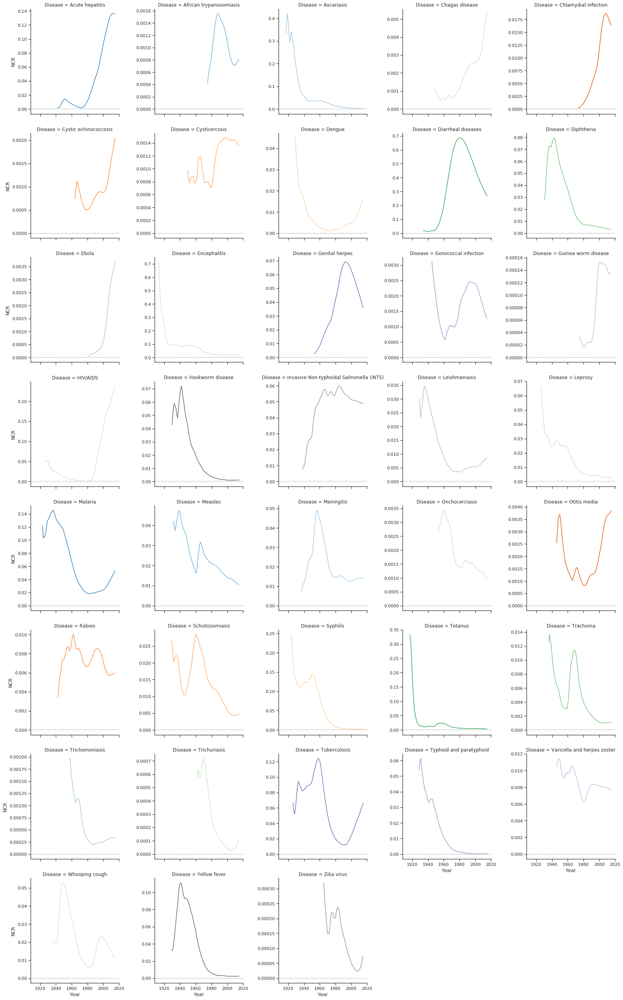

In [311]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations_smooth[disease_citations_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

#### Citations/DALYs

In [349]:
pubmed_gdb_citation["Citation/DALYs"] = pubmed_gdb_citation["Citations"] /pubmed_gdb_citation["DALY"]

In [352]:
citation_daly = pubmed_gdb_citation.sort(["Disease", "Year"])

In [353]:
citation_daly = citation_daly[citation_daly["DALY"] > 0]

In [357]:
citation_daly["Citation/DALYs-log"] = np.log(citation_daly["Citation/DALYs"])

In [359]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Citation_DALYs.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(citation_daly.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "Citation/DALYs")
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

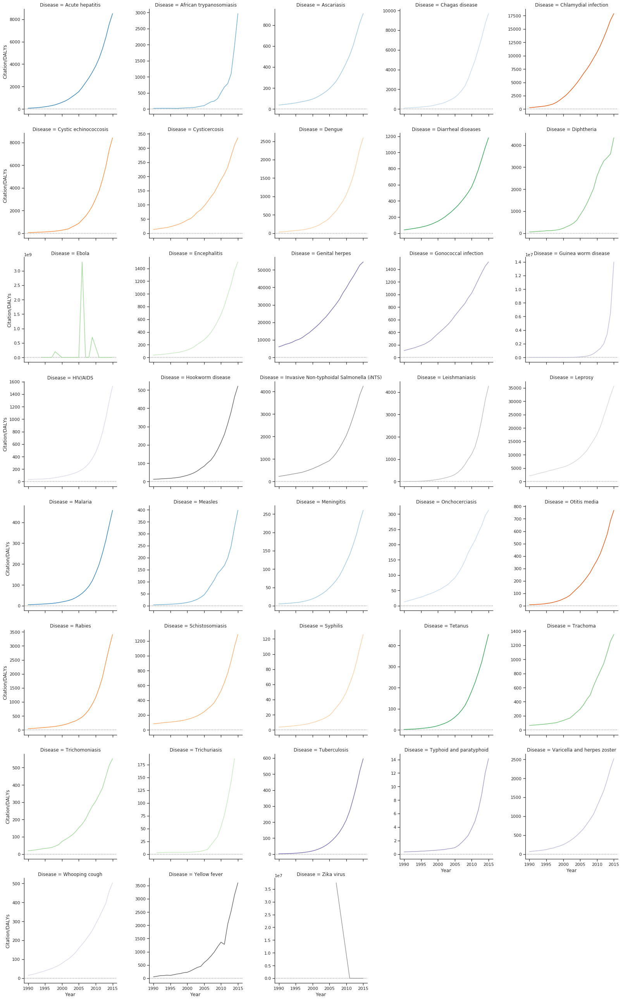

In [394]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Citation/DALYs")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [382]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Papers/Citation_DALYs_log.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(citation_daly.to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "Citation/DALYs-log", sharey=True)
#         plt.title('')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

#### Corrolation

In [363]:

def get_lags(cc):
    """
    Return array with lags

    :param cc: Cross-correlation returned by correlate_maxlag.
    :return: lags
    """
    mid = (len(cc) - 1) / 2
    if len(cc) % 2 == 1:
        mid = int(mid)
    return np.arange(len(cc)) - mid

def normolized_cross_corr(a, b):
    a = (a - np.mean(a)) / (np.std(a) * len(a))
    b = (b - np.mean(b)) / (np.std(b))
    c = np.correlate(a, b, 'full')
    xcorr = SFrame()
    xcorr["shift"] = get_lags(c)
    xcorr["corr"] = c
    return xcorr

In [373]:
def get_d(sf_corr, diseases_id):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[0], data[1].sort_values("Year")
            
def get_diseases_cross_corr(diseases_id, corr, corr_fileds):
    res =SFrame()
    for title, data in tqdm(get_d(corr, diseases_id)):
#         print(title)
#         data = data[data["year"]<2019]
        values = data[corr_fileds[0]]
        num = data[corr_fileds[1]]
#         num_5 = data["Number of papers (Ref >5)"]
        corr = normolized_cross_corr(values, num)
#         print(corr[corr["shift"]==0])
        corr["diseases"]= [title]*len(corr)
#         corr2 = normolized_cross_corr(values, num_5)
#         corr["corr_5"] = corr2["corr"]
        res = res.append(corr)
    return res
    

In [325]:
dff_corr =  pubmed_gdb.merge(disease_citations,left_on=["id", "year"], right_on=["id", "Year"])

In [367]:
dff_corr = pubmed_gdb_citation.to_dataframe()

In [374]:
corr_npr = get_diseases_cross_corr(disease_names, dff_corr,("DALY", "NPR"))
corr_papers = get_diseases_cross_corr(disease_names, dff_corr,("DALY", "Number of papers"))
corr_cnr = get_diseases_cross_corr(disease_names, dff_corr,("DALY", "NCR"))
corr_citations = get_diseases_cross_corr(disease_names, dff_corr,("DALY", "Citations"))

In [375]:
def get_best_corr(res, suffixes):
    return res[(res['shift']<=0)&(res['shift']>-5)].groupby("diseases", operations={f"max_shift_corr_{suffixes}": agg.ARGMAX("corr","shift"),f"max_corr_{suffixes}": agg.ARGMAX("corr","corr"),
                                   f"min_shift_corr_{suffixes}": agg.ARGMIN("corr","shift"),f"min_corr_{suffixes}": agg.ARGMIN("corr","corr")})

In [376]:
corr = get_best_corr(corr_npr,"NPR").join(get_best_corr(corr_papers, "Papers"), on={"diseases":"diseases"}).join(get_best_corr(corr_cnr, "CNR"), on={"diseases":"diseases"}).join(get_best_corr(corr_citations, "Citations"), on={"diseases":"diseases"})

In [377]:
corr.save("output/Papers/corr.csv", "csv")

## Pubmed

In [8]:
diseases_pubmed = load_sframe("Data/pubmed/diseases_pubmed.sframe")

### Publications Corrolation Promed

In [7]:
def join_pubmed_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","year"], {"Number of papers": agg.COUNT()})
    sf_corr = diseases_pub_count.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [8]:
pubmed_corr = join_pubmed_promed(diseases_pubmed, diseases_id, diseases_occurrences)

NameError: name 'diseases_occurrences' is not defined

### Publications Corrolation GBD

In [84]:
gdb = SFrame.read_csv("Data/gdb/gdb.csv")
# gdb["cause"] = gdb["cause"].apply(lambda x: x.lower())

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 100 lines in 0.240041 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,str,str,str,str,str,int,float,float,float]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/gdb/gdb.csv

Parsing completed. Parsed 22176 lines in 0.057894 secs.

In [85]:
gdb = gdb[(gdb["metric"]=="Rate")&(gdb["sex"]=="Both")]

In [10]:
diseases_pubmed = diseases_pubmed.join(diseases_id, on={"disease":"diseases"})

In [72]:
len(gdb["cause"].unique())

50

In [74]:
gdb_diseases

id,disease,GDB
100,Ascariasis,Ascariasis
72,Bacillus cereus foodpoisoning ...,Diarrheal diseases
12,Borna virus encephalitis,Encephalitis
23,Brainerd diarrhea,Diarrheal diseases
243,California encephalitis,Encephalitis
42,Campylobacteriosis,Diarrheal diseases
200,Chlamydia,Chlamydial infection
331,Cysticercosis,Cysticercosis
78,Dengue,Dengue
298,Diphtheria,Diphtheria


In [75]:
len(gdb)

22176

In [79]:
diseases_id

diseases,id
reye's syndrome,152
brain abscess,254
murray valley and kunjin,323
wesselsbron,311
spotted fevers,102
entomophthoromycosis,178
hendra virus,300
porocephaliasis,151
chromomycosis,89
bejel,294


In [11]:
gbd = gbd.join(diseases_id, on={"cause":"diseases"})

In [12]:
def join_gdb(academic_sf, diseases_occurrences):
    diseases_pub_count = academic_sf.groupby(["id","year"], {"Number of papers": agg.COUNT()})
#     sf_corr = diseases_pub_count.join(diseases_id)
#     sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return diseases_pub_count.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [13]:
pubmed_gdb = join_gdb(diseases_pubmed, gbd)

In [14]:
dalys = pubmed_gdb[pubmed_gdb["measure"] =="DALYs (Disability-Adjusted Life Years)"]
deaths = pubmed_gdb[pubmed_gdb["measure"] =="Deaths"]

In [15]:
pubmed_gdb = dalys.merge(deaths,how="left",left_on=["id","year", "metric"],right_on=["id","year", "metric"], suffixes=("","_Deaths"))

In [16]:
pubmed_gdb = pubmed_gdb[["id", "year", "Number of papers","cause","metric",  'val','val_Deaths']]

In [17]:
pubmed_gdb = pubmed_gdb[pubmed_gdb["metric"] =="Rate"]

Normlize paper number:

In [ ]:
diseases_pub_count = diseases_pubmed.groupby(["id","year"], {"Number of papers": agg.COUNT()})
diseases_pub_count = diseases_pub_count.join(SFrame(disease_names), {"id":"id"})

In [20]:
papers_year = diseases_pub_count.to_dataframe().groupby("year").sum()["Number of papers"]

In [21]:
diseases_pub_count = diseases_pub_count.to_dataframe().merge(papers_year,left_on="year", right_index=True)
diseases_pub_count["Normalized Number of papers"] = diseases_pub_count["Number of papers_x"] / diseases_pub_count["Number of papers_y"]

In [155]:
# pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

In [22]:
pubmed_gdb = pubmed_gdb.merge(papers_year,left_on="year", right_index=True)

In [23]:
pubmed_gdb["Normalized Number of papers"] = pubmed_gdb["Number of papers_x"] / pubmed_gdb["Number of papers_y"]

Join with Promed

In [41]:
pubmed_gdb[pubmed_gdb["cause"]=="ascariasis"].sort_values("year").corr()

,id,year,Number of papers_x,val,val_Deaths,Number of papers_y,Normalized Number of papers
id,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,NaN,1.000000,-0.652292,-0.994539,-0.991176,0.954993,-0.934676
Number of papers_x,NaN,-0.652292,1.000000,0.672773,0.684969,-0.545974,0.871612
val,NaN,-0.994539,0.672773,1.000000,0.997113,-0.928746,0.941281
val_Deaths,NaN,-0.991176,0.684969,0.997113,1.000000,-0.909432,0.942724
Number of papers_y,NaN,0.954993,-0.545974,-0.928746,-0.909432,1.000000,-0.865614
Normalized Number of papers,NaN,-0.934676,0.871612,0.941281,0.942724,-0.865614,1.000000


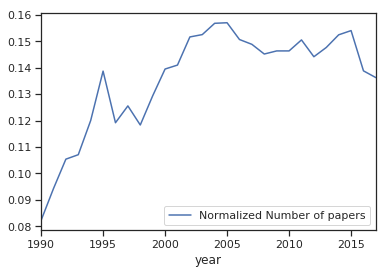

In [82]:
pubmed_gdb[pubmed_gdb["cause"]=="acute hepatitis"].sort_values("year").plot(x="year", y="Normalized Number of papers")

In [27]:
# pubmed_gdb_= pubmed_gdb_.merge(promed_diseases_agg.to_dataframe(), how="left", left_on=["id","pubdate"],  right_on=["id","year"])

## Aminer

In [121]:
diseases_miner = load_sframe("Data/aminer/diseases_aminer.sframe")
diseases_miner["year"] = diseases_miner["year"].astype(int)

### Citations to time

In [122]:
disease_citations = diseases_miner.groupby(["id","year"], {"Citations": agg.SUM("n_citation")})

In [123]:
citations_year = diseases_miner.groupby(["year"], operations={"Total Citations": agg.SUM("n_citation")})

In [124]:
disease_citations = disease_citations.join(citations_year)

In [125]:
disease_citations["Citations Norm"] = disease_citations["Citations"]/disease_citations["Total Citations"]

In [33]:
def join_aminer_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","year"], {"Number of papers": agg.COUNT()})
    sf_corr = diseases_pub_count.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","year"], {"Number of papers":agg.SUM("Number of papers")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","year":"year"}).to_dataframe()

In [34]:
aminer_corr = join_aminer_promed(diseases_miner, diseases_id, diseases_occurrences)

NameError: name 'diseases_occurrences' is not defined

In [163]:
citations_race = convert_to_barchart_format(SFrame(disease_citations),"Disease",count_column="Citations" )

In [164]:
citations_race.to_csv("output/citations_race.csv", index=False)

## Semantic Scholar

In [ ]:
diseases_sm = load_sframeload_sframe("/data/semantic-scholar/s2-corpus-small.sframe")
diseases_s["year"] = diseases_miner["year"].astype(int)

## Data Fusion

In [107]:
sm_papers_year = diseases_sm.groupby("year",{"Semantic": agg.COUNT()})

In [47]:
aminer_papers_year = diseases_miner.groupby("year",{"Aminer": agg.COUNT()})

In [48]:
pubmed_papers_year = diseases_pubmed.groupby("year",{"PubMed":agg.COUNT()})

In [51]:
mag_papers_year =  diseases_mag.groupby("Paper publish year",{"MAG":agg.COUNT()})

In [52]:
df = aminer_papers_year.join(pubmed_papers_year,{"year":"year"}).join(mag_papers_year,{"year":"Paper publish year"}).sort("year")

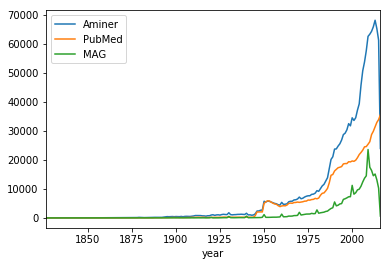

In [53]:
df.sort("year").to_dataframe().plot(x="year")

In [54]:
df =df.rename({"year":"Year"})

In [55]:
df2 = df.pack_columns(column_names=["MAG","PubMed","Aminer"], dtype=dict, new_column_name='Papers').stack("Papers", new_column_name=['Dataset', 'Total Papers'])

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/plotly/express/_doc.py:353: DeprecationWarning:

inspect.getargspec() is deprecated since Python 3.0, use inspect.signature() or inspect.getfullargspec()



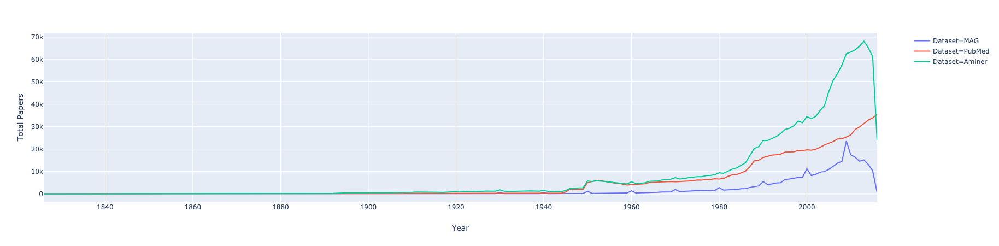

In [56]:
import plotly.express as px

fig = px.line(df2.to_dataframe(), x="Year", y="Total Papers",color="Dataset")
fig.show()

### Pubmed publications - GBD - Aminer Citation

In [272]:
pubmed_gdb["val_Deaths"] = pubmed_gdb["val_Deaths"].fillna(0)

In [273]:
pubmed_gdb_citation = SFrame(pubmed_gdb).join(disease_citations, on={"id":"id", "year":"year"})

In [274]:
pubmed_gdb_citation = pubmed_gdb_citation.to_dataframe()

Draw results:

In [275]:
pubmed_gdb_citation.id = pubmed_gdb_citation.id.astype(int)

In [276]:
pubmed_gdb_citation = pubmed_gdb_citation.sort_values(["id","year"])

In [182]:

output_folder = "output"
temp_folder = "temp"
matplotlib
os.makedirs(output_folder, exist_ok=True)
des = list(get_d(pubmed_gdb_citation, disease_names))
for i, curr_f in enumerate(tqdm(chunks(des, 1), total=((len(des) // 1)+1))):
    draw_probas_graph(curr_f, str(i), temp_folder,{ "NCR": "Citations Norm","NPR":"Normalized Number of papers","Number of Papers":"Number of papers_x","DALYs":"val","Deaths":"val_Deaths", "Number of Citations": "Citations"}, "year")
create_pdf(temp_folder,f"{output_folder}/gdb3-2")

  3%|▎         | 1/39 [00:00<00:11,  3.22it/s]/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:32: RuntimeWarning:

divide by zero encountered in log

 51%|█████▏    | 20/39 [00:06<00:05,  3.24it/s]/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/matplotlib/pyplot.py:514: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).

 97%|█████████▋| 38/39 [00:12<00:00,  2.58it/s]


<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

...

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

In [277]:
sf = SFrame(pubmed_gdb_citation)

In [278]:
sf = sf.rename({"val":"DALY"})

#### NPR

In [238]:
pubmed_gdb_citation = pubmed_gdb_citation.merge(disease_names.to_dataframe(),left_on="id",right_on="id")

In [280]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"Normalized Number of papers":"NPR","year":"Year","Citations Norm":"NCR"},axis=1)

In [240]:
diseases_pub_count = diseases_pub_count.rename({"Normalized Number of papers":"NPR","year":"Year"},axis=1)

In [241]:
diseases_pub_count = diseases_pub_count.sort_values(["Disease","Year"])

In [248]:
pubmed_gdb_citation = pubmed_gdb_citation.rename({"Disease_x":"Disease"}, axis=1)

In [282]:
pubmed_gdb_citation = pubmed_gdb_citation.sort_values(["Disease","Year"])

In [283]:
pubmed_gdb_citation3 = pubmed_gdb_citation.copy()

In [284]:
pubmed_gdb_citation3["NPR"] = np.log(pubmed_gdb_citation3["NPR"] )
pubmed_gdb_citation3["NCR"] = np.log(pubmed_gdb_citation3["NCR"] )

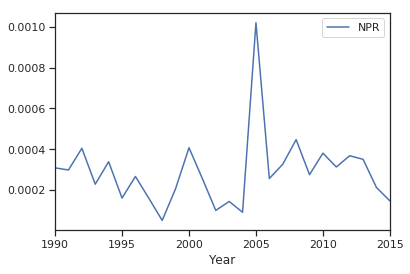

In [285]:
pubmed_gdb_citation[pubmed_gdb_citation["id"]==37].plot(x="Year", y="NPR")

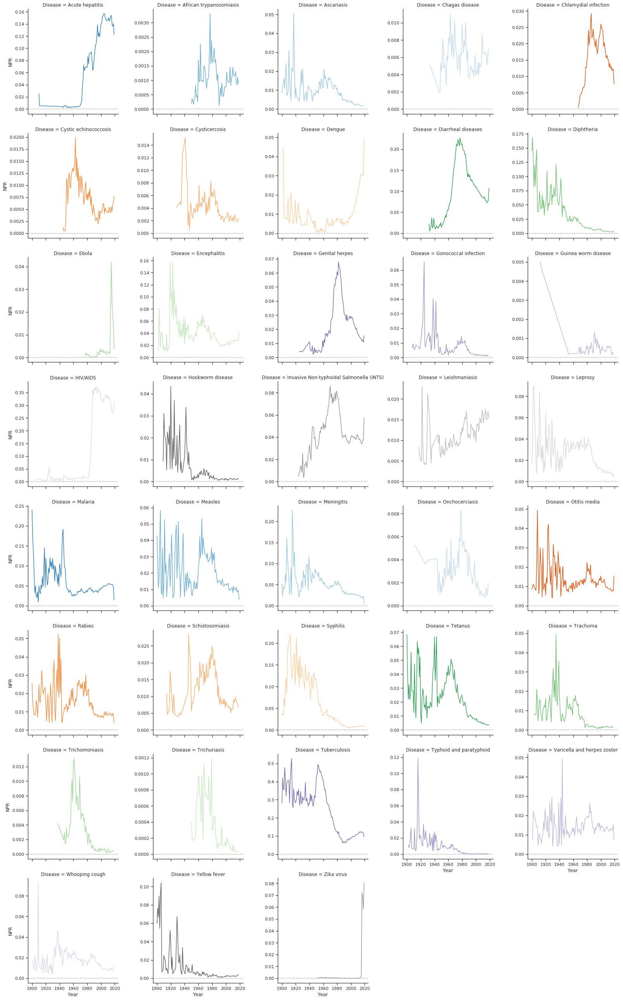

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count[diseases_pub_count["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [380]:
diseases_pub_count = diseases_pub_count.sort_values(["Disease", "Year"])

In [381]:
diseases_pub_count_smooth= diseases_pub_count[["Disease","Number of papers_x","Number of papers_y"]].groupby("Disease").rolling(5).sum()

In [385]:
diseases_pub_count_smooth = diseases_pub_count_smooth.reset_index()

In [388]:
diseases_pub_count_smooth["Year"] = diseases_pub_count["Year"].values

In [390]:
diseases_pub_count_smooth["NPR"] = diseases_pub_count_smooth["Number of papers_x"]/diseases_pub_count_smooth["Number of papers_y"]

In [391]:
diseases_pub_count_smooth = diseases_pub_count_smooth.sort_values(["Disease", "Year"])

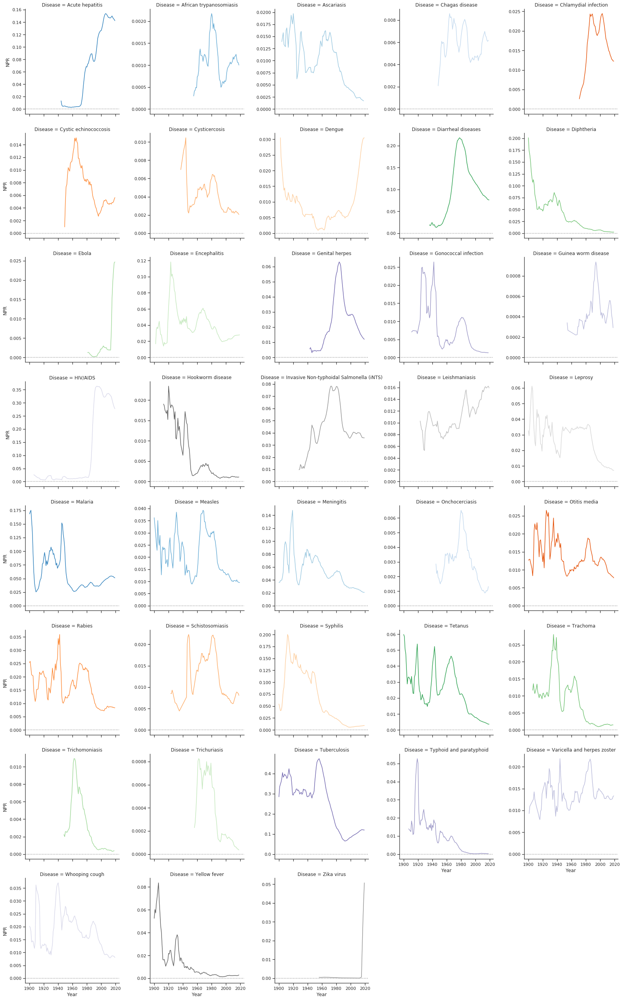

In [392]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(diseases_pub_count_smooth[diseases_pub_count_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 ,sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NPR")

# Adjust the tick positions and labels
# grid.set(xlim=(1900, 2018))

# Adjust the arrangement of the plots


#### NCR

In [302]:
disease_citations = disease_citations.rename({"year":"Year","Citations Norm":"NCR"})
disease_citations = disease_citations.join(disease_names, {"id":"id"})
disease_citations = disease_citations.sort(["Disease", "Year"])

In [303]:
disease_citations = disease_citations.to_dataframe()

In [304]:
disease_citations = disease_citations[disease_citations["Year"].notna()]

In [305]:
disease_citations = disease_citations[disease_citations["Year"]<2017]

In [306]:
disease_citations = disease_citations.reset_index()

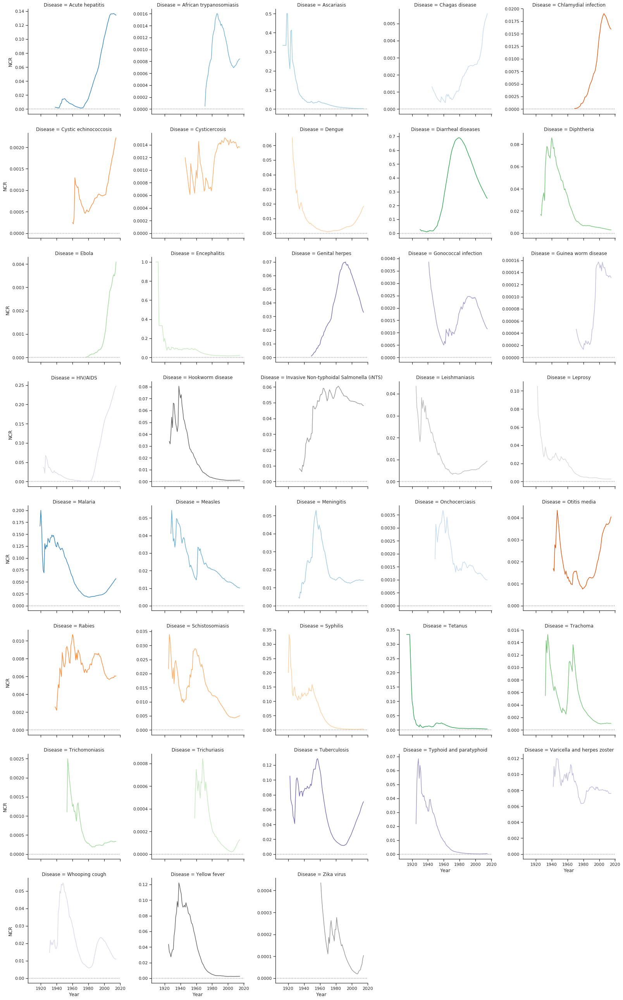

In [343]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations[disease_citations["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [307]:
disease_citations_smooth= disease_citations[["Disease","Citations","Total Citations"]].groupby("Disease").rolling(5).sum()

In [308]:
disease_citations_smooth = disease_citations_smooth.reset_index()

In [309]:
disease_citations_smooth["Year"] = disease_citations["Year"]

In [310]:
disease_citations_smooth["NCR"] = disease_citations_smooth["Citations"]/disease_citations_smooth["Total Citations"]

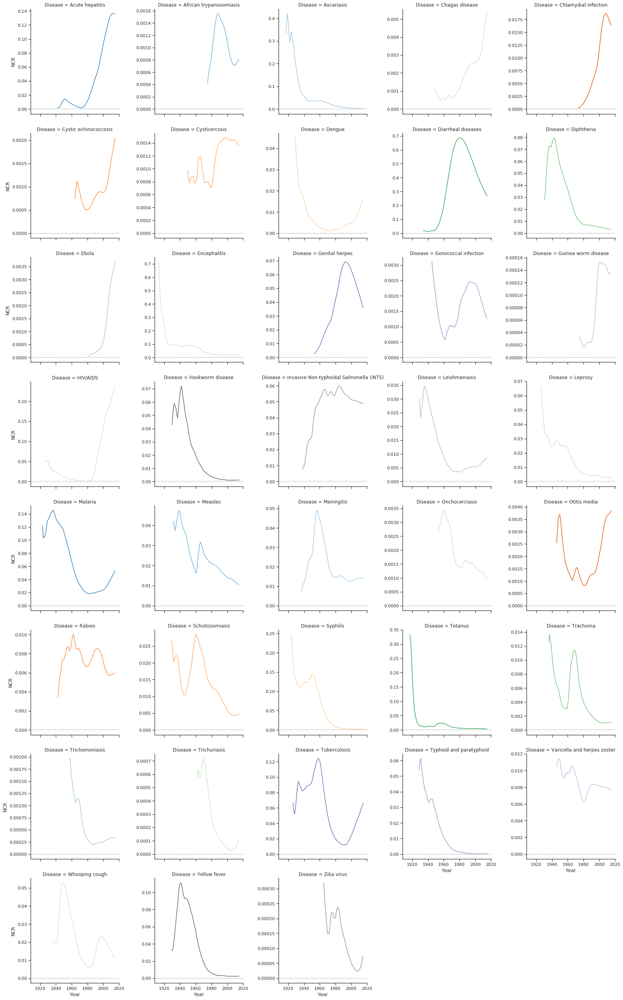

In [311]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(disease_citations_smooth[disease_citations_smooth["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "NCR")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

#### Citations/DALYs

In [313]:
pubmed_gdb_citation["Citation/DALYs"] = pubmed_gdb_citation["Citations"] /pubmed_gdb_citation["val"]

In [314]:
citation_daly = pubmed_gdb_citation.rename({"year":"Year"})
citation_daly = citation_daly.sort_values(["Disease", "Year"])

In [315]:
citation_daly = citation_daly[citation_daly["val"] > 0]

In [401]:
citation_daly[citation_daly["Disease"]=="Diarrheal diseases"]

,id,Year,Number of papers_x,cause,metric,val,val_Deaths,Number of papers_y,NPR,Citations,Total Citations,NCR,Disease,Citation/DALYs,Citation/DALYs-log
732,6,1990,2160,diarrheal diseases,Rate,3311.936438,47.792985,16180,0.133498,137454.0,234233.0,0.586826,Diarrheal diseases,41.502608,3.725756
192,6,1991,2316,diarrheal diseases,Rate,3216.586615,46.718171,16746,0.138302,149918.0,261543.0,0.573206,Diarrheal diseases,46.607792,3.841768
629,6,1992,2255,diarrheal diseases,Rate,3082.256108,45.148800,17292,0.130407,163074.0,292816.0,0.556916,Diarrheal diseases,52.907349,3.968542
478,6,1993,2182,diarrheal diseases,Rate,2967.046487,43.677116,17469,0.124907,176194.0,323296.0,0.544993,Diarrheal diseases,59.383633,4.084019
371,6,1994,2263,diarrheal diseases,Rate,2860.093375,42.251506,17698,0.127868,190728.0,359146.0,0.531060,Diarrheal diseases,66.685935,4.199994
104,6,1995,2261,diarrheal diseases,Rate,2748.645544,40.824683,18615,0.121461,205431.0,400307.0,0.513184,Diarrheal diseases,74.738993,4.314002
863,6,1996,2268,diarrheal diseases,Rate,2619.562104,39.208237,18734,0.121063,221337.0,443968.0,0.498543,Diarrheal diseases,84.493893,4.436679
101,6,1997,2138,diarrheal diseases,Rate,2509.130641,37.957329,18733,0.114130,240831.0,499384.0,0.482256,Diarrheal diseases,95.981850,4.564159
316,6,1998,2214,diarrheal diseases,Rate,2416.285773,36.851092,19369,0.114306,267217.0,573042.0,0.466313,Diarrheal diseases,110.589982,4.705830
90,6,1999,2195,diarrheal diseases,Rate,2316.319081,35.607723,19303,0.113713,297627.0,661126.0,0.450182,Diarrheal diseases,128.491365,4.855862


In [341]:
citation_daly["Citation/DALYs-log"] = np.log(citation_daly["Citation/DALYs"])

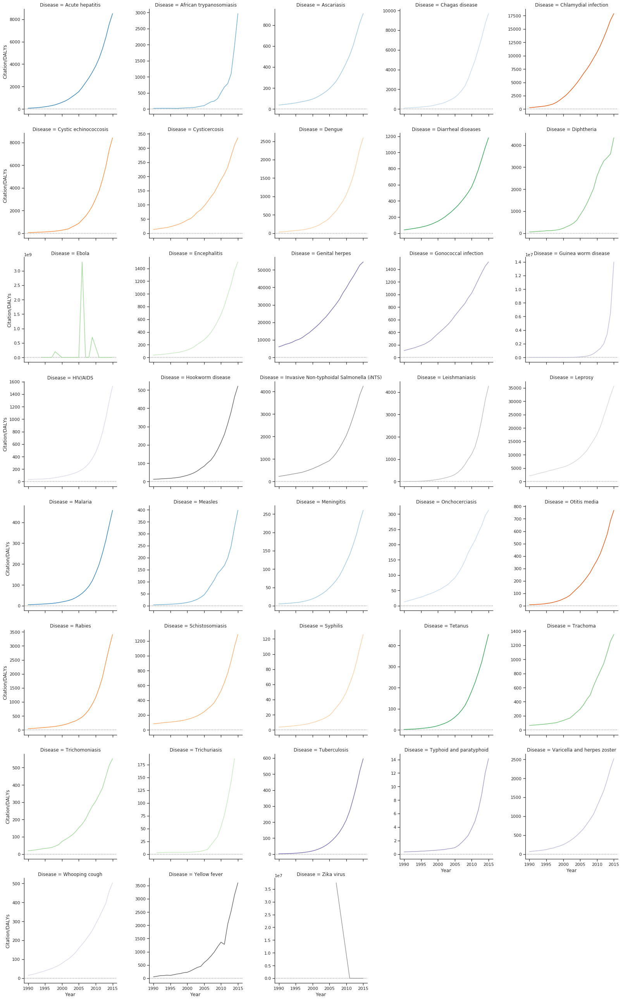

In [394]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Citation/DALYs")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

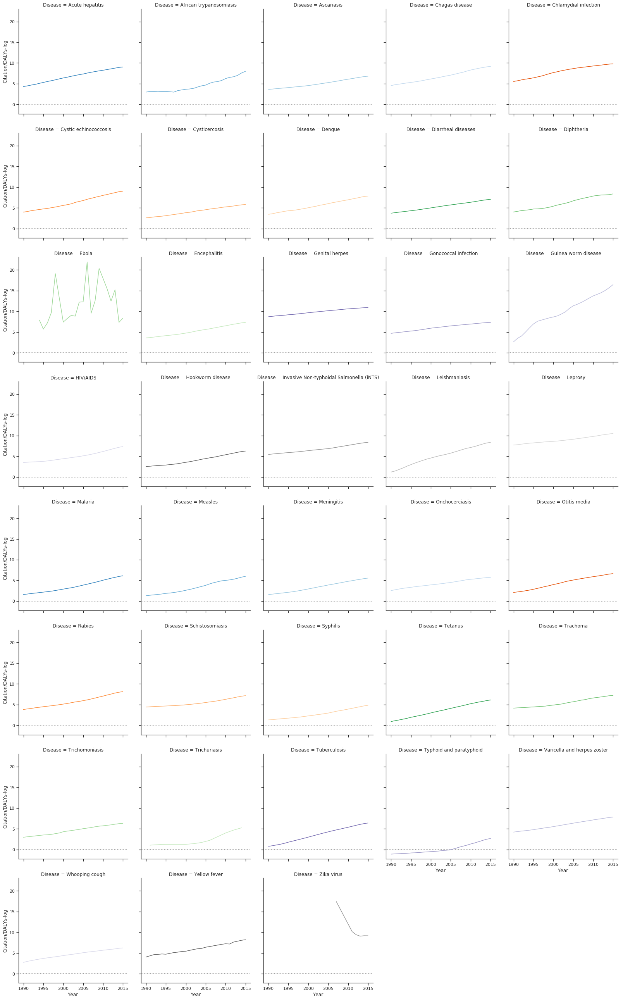

In [342]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=True)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Citation/DALYs-log")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

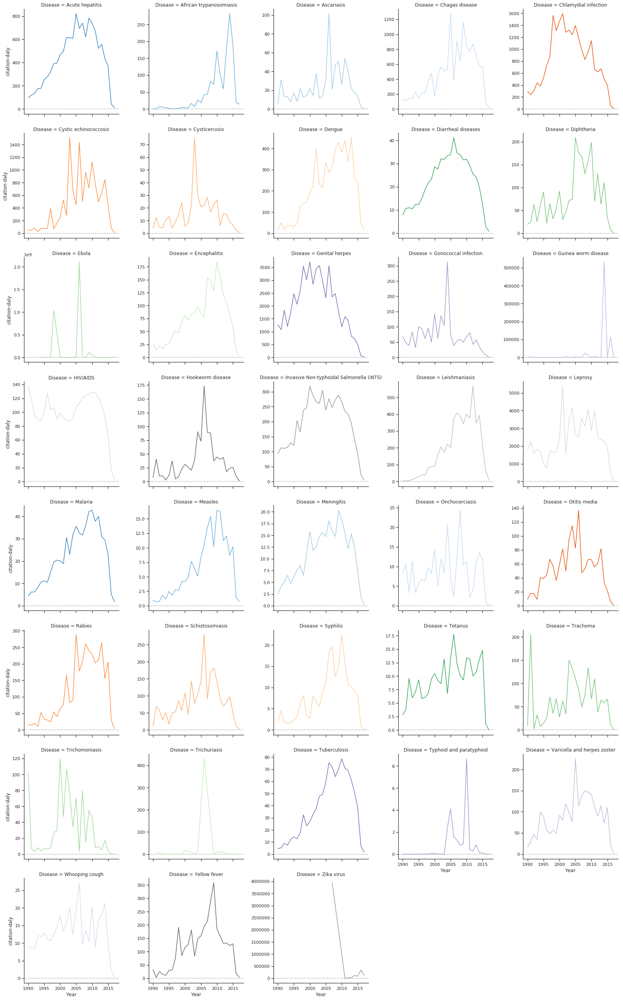

In [148]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")



# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(citation_daly[citation_daly["Year"]>=1900], col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5, sharey=False)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "citation-daly")

# Adjust the tick positions and labels
# grid.set(xticks=np.arange(5), yticks=[-3, 3],
#          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

,id,Year,Number of papers_x,cause,metric,val,val_Deaths,Number of papers_y,NPR,Citations,Total Citations,NCR,Disease,citation-daly
954,36,1990,1331,acute hepatitis,Rate,157.744506,2.722668e+00,16180,0.082262,15268.0,133181.0,0.114641,Acute hepatitis,9.678942e+01
955,36,1991,1579,acute hepatitis,Rate,156.667007,2.709583e+00,16746,0.094291,18613.0,158499.0,0.117433,Acute hepatitis,1.188061e+02
956,36,1992,1823,acute hepatitis,Rate,154.865608,2.688581e+00,17292,0.105424,21065.0,164994.0,0.127671,Acute hepatitis,1.360212e+02
957,36,1993,1871,acute hepatitis,Rate,152.640338,2.661595e+00,17469,0.107104,27024.0,173725.0,0.155556,Acute hepatitis,1.770436e+02
958,36,1994,2124,acute hepatitis,Rate,149.181443,2.618175e+00,17698,0.120014,26509.0,200852.0,0.131983,Acute hepatitis,1.776964e+02
959,36,1995,2582,acute hepatitis,Rate,146.232244,2.581607e+00,18615,0.138705,36985.0,239852.0,0.154199,Acute hepatitis,2.529196e+02
960,36,1996,2233,acute hepatitis,Rate,141.841966,2.527227e+00,18734,0.119195,39445.0,287357.0,0.137268,Acute hepatitis,2.780912e+02
961,36,1997,2352,acute hepatitis,Rate,139.433800,2.506556e+00,18733,0.125554,44666.0,302609.0,0.147603,Acute hepatitis,3.203384e+02
962,36,1998,2292,acute hepatitis,Rate,136.641296,2.475204e+00,19369,0.118333,53510.0,366243.0,0.146105,Acute hepatitis,3.916093e+02
963,36,1999,2497,acute hepatitis,Rate,133.889070,2.438440e+00,19303,0.129358,53038.0,352893.0,0.150295,Acute hepatitis,3.961339e+02


#### Corrolation

In [327]:

def get_lags(cc):
    """
    Return array with lags

    :param cc: Cross-correlation returned by correlate_maxlag.
    :return: lags
    """
    mid = (len(cc) - 1) / 2
    if len(cc) % 2 == 1:
        mid = int(mid)
    return np.arange(len(cc)) - mid

def normolized_cross_corr(a, b):
    a = (a - np.mean(a)) / (np.std(a) * len(a))
    b = (b - np.mean(b)) / (np.std(b))
    c = np.correlate(a, b, 'full')
    xcorr = SFrame()
    xcorr["shift"] = get_lags(c)
    xcorr["corr"] = c
    return xcorr

In [328]:
def get_diseases_cross_corr(diseases_id, corr, corr_fileds):
    res =SFrame()
    for title, data in tqdm(get_d(corr, diseases_id)):
#         print(title)
#         data = data[data["year"]<2019]
        values = data[corr_fileds[0]]
        num = data[corr_fileds[1]]
#         num_5 = data["Number of papers (Ref >5)"]
        corr = normolized_cross_corr(values, num)
#         print(corr[corr["shift"]==0])
        corr["diseases"]= [title]*len(corr)
#         corr2 = normolized_cross_corr(values, num_5)
#         corr["corr_5"] = corr2["corr"]
        res = res.append(corr)
    return res
    

In [325]:
dff_corr =  pubmed_gdb.merge(disease_citations,left_on=["id", "year"], right_on=["id", "Year"])

In [333]:
corr_npr = get_diseases_cross_corr(disease_names, dff_corr,("val", "Normalized Number of papers"))
corr_papers = get_diseases_cross_corr(disease_names, dff_corr,("val", "Number of papers_x"))
corr_cnr = get_diseases_cross_corr(disease_names, dff_corr,("val", "NCR"))
corr_citations = get_diseases_cross_corr(disease_names, dff_corr,("val", "Citations"))

In [335]:
def get_best_corr(res, suffixes):
    return res[(res['shift']<=0)&(res['shift']>-5)].groupby("diseases", operations={f"max_shift_corr_{suffixes}": agg.ARGMAX("corr","shift"),f"max_corr_{suffixes}": agg.ARGMAX("corr","corr"),
                                   f"min_shift_corr_{suffixes}": agg.ARGMIN("corr","shift"),f"min_corr_{suffixes}": agg.ARGMIN("corr","corr")})

In [336]:
corr = get_best_corr(corr_npr,"NPR").join(get_best_corr(corr_papers, "Papers"), on={"diseases":"diseases"}).join(get_best_corr(corr_cnr, "CNR"), on={"diseases":"diseases"}).join(get_best_corr(corr_citations, "Citations"), on={"diseases":"diseases"})

In [337]:
corr.save("output/corr2.csv", "csv")

In [156]:
pubmed_gdb.head(2)

,id,year,Number of papers_x,cause,metric,val,val_DALYs,Number of papers_y,Number of papers,Normalized Number of papers
2,18,1990,169,syphilis,Rate,2.482625,215.058343,15222,15222,0.011102
5,19,1990,347,chlamydial infection,Rate,0.022875,5.043920,15222,15222,0.022796


In [194]:
res = get_diseases_cross_corr(diseases_id, pubmed_gdb,("val", "Number of papers_x"))

In [195]:
best_corr = res[(res['shift']<=0)&(res['shift']>-5)].groupby("diseases", operations={"max_shift_corr": agg.ARGMAX("corr","shift"),"max_corr": agg.ARGMAX("corr","corr"),
                                   "min_shift_corr": agg.ARGMIN("corr","shift"),"min_corr": agg.ARGMIN("corr","corr")})

In [196]:
best_corr.sort("min_corr")

diseases,max_shift_corr,max_corr,min_shift_corr,min_corr
36: Hepatitis B,-4,-0.5489492898733306,0,-0.9833112334347448
27: Tuberculosis,-4,-0.6506982280896545,0,-0.9751966331002979
31: Encephalitis,-4,-0.7160376487668838,0,-0.9460447765070261
33: Varicella And HerpesZoster ...,-4,-0.5385472209568446,0,-0.9010380794946572
22: Meningitis,-4,-0.6640729989478517,0,-0.8960126669429479
21: Rabies,-4,-0.6923911283331452,0,-0.8951571096300697
23: Cystic Echinococcosis,-4,-0.6492277617074927,0,-0.8838551922548883
18: Syphilis,-4,-0.7343071184736405,0,-0.8833257266140158
8: AfricanTrypanosomiasis ...,-4,-0.4642394425794624,0,-0.840576951254568
0: Chagas Disease,-4,-0.6763581660491724,0,-0.8335930391537093


In [199]:
best_corr.sort("max_corr",False).print_rows(30)

+-------------------------------+----------------+---------------------+----------------+
|            diseases           | max_shift_corr |       max_corr      | min_shift_corr |
+-------------------------------+----------------+---------------------+----------------+
|            3: Zikv            |       0        |  0.9972279646113171 |       -4       |
|           10: Dengue          |       0        |  0.9921895010569646 |       -4       |
|            2: Ebola           |       -1       |  0.8344253378871697 |       -4       |
|          16: Tetanus          |       0        |  0.8207777246330292 |       -4       |
|         34: Diphtheria        |       -1       |  0.7015877880971273 |       -4       |
|         15: Ascariasis        |       0        |  0.6849690290880027 |       -4       |
|         28: Salmonella        |       -4       |  0.5275979727207039 |       0        |
|            12: Hiv            |       -4       | 0.48254347592689173 |       0        |
|         

In [63]:
best_corr.save("best_corr_pubmed2.csv","csv")